In [45]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.14.7 2.3.4 2.3.3 1.7.2 3.10.7


In [24]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2666         # last 4 digits of your student ID, as an integer (0421 -> 421)
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


In [25]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]   # members of voting and stacking in Parts 3-4

# 1. Bagging and out-of-bag estimates
A bootstrap sample draws n rows from n with replacement. A row that a tree never saw is out of bag (OOB) for that tree. Here you rebuild scikit-learn's OOB estimate yourself, compare bagged learners with the learners they are made of, and compare three estimates of the same forest.

In [26]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    import numpy as np

    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False   # dtype=int so that an empty list works
    return mask

In [27]:
# the three examples from the task, plus the type/shape and "arguments unchanged" rules
assert oob_mask([0, 2, 2], 5).tolist() == [False, True, False, True, True]
assert oob_mask([], 3).tolist() == [True, True, True]
assert oob_mask(np.array([3, 0]), 4).tolist() == [False, True, True, False]

idx = np.array([3, 0, 3])
idx_before = idx.copy()
m = oob_mask(idx, 4)
assert (idx == idx_before).all() and isinstance(m, np.ndarray) and m.dtype == bool and m.shape == (4,)
print("oob_mask: all examples pass")

oob_mask: all examples pass


### 1.1 Out-of-bag share per tree

In [28]:
bag.fit(X_train, y_train)
n = len(X_train)

oob_shares = np.array([oob_mask(s, n).mean() for s in bag.estimators_samples_])
mean_oob_share = oob_shares.mean()

print(f"n (training rows)                  : {n}")
print(f"mean out-of-bag share over {len(oob_shares)} trees: {mean_oob_share:.4f}")
print(f"mean in-bag share                  : {1 - mean_oob_share:.4f}")
print(f"formula (1 - 1/n)^n                : {(1 - 1 / n) ** n:.4f}")
print(f"formula 1 - (1 - 1/n)^n            : {1 - (1 - 1 / n) ** n:.4f}")

n (training rows)                  : 3153
mean out-of-bag share over 100 trees: 0.3680
mean in-bag share                  : 0.6320
formula (1 - 1/n)^n                : 0.3678
formula 1 - (1 - 1/n)^n            : 0.6322


### 1.2 Out-of-bag accuracy by hand

In [29]:
votes = np.zeros((n, 2), dtype=int)
for tree_k, samples_k in zip(bag.estimators_, bag.estimators_samples_):
    m = oob_mask(samples_k, n)
    pred = tree_k.predict(X_train[m])
    votes[np.flatnonzero(m), pred] += 1          # one vote for the predicted class, only for rows out of bag

oob_pred = votes.argmax(axis=1)                  # a tie goes to class 0
oob_acc_hand = (oob_pred == y_train).mean()
print(f"rows that were out of bag for no tree at all: {(votes.sum(axis=1) == 0).sum()}")
print(f"my out-of-bag accuracy : {oob_acc_hand:.4f}")
print(f"bag.oob_score_         : {bag.oob_score_:.4f}")
print("identical:", np.isclose(oob_acc_hand, bag.oob_score_))

rows that were out of bag for no tree at all: 0
my out-of-bag accuracy : 0.9340
bag.oob_score_         : 0.9340
identical: True


### 1.3 Five models on the same folds

In [30]:
from sklearn.model_selection import cross_validate


def fold_table(scores):
    """Fold scores, mean and std (np.std, ddof=0) of every model in a dict name -> five scores."""
    t = pd.DataFrame({name: s for name, s in scores.items()}).T
    t.columns = [f"fold {i}" for i in range(1, t.shape[1] + 1)]
    t["mean"] = [s.mean() for s in scores.values()]
    t["std"] = [s.std() for s in scores.values()]
    return t


def paired_table(scores, pairs):
    """Paired fold differences A - B for every (A, B) in pairs, with mean, std and the 'inside the fold spread' rule."""
    rows = {}
    for a, b in pairs:
        d = scores[a] - scores[b]
        rows[f"{a} - {b}"] = list(d) + [d.mean(), d.std(), abs(d.mean()) <= d.std()]
    t = pd.DataFrame(rows).T
    t.columns = [f"fold {i}" for i in range(1, len(d) + 1)] + ["mean", "std", "inside spread"]
    return t


five_models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
fold_scores = {name: cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
               for name, model in five_models.items()}

display(fold_table(fold_scores).round(4))
print("paired fold differences (accuracy):")
display(paired_table(fold_scores, [("bag", "tree"), ("rf", "tree"), ("bag_lr", "lr")]).round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
tree,0.9113,0.9303,0.9097,0.9000,0.9095,0.9121,0.0099
bag,0.9239,0.9493,0.9334,0.9206,0.9222,0.9299,0.0107
rf,0.9366,0.9556,0.9414,0.9476,0.9508,0.9464,0.0067
lr,0.9319,0.9525,0.9366,0.9333,0.9429,0.9394,0.0075
bag_lr,0.9334,0.9525,0.9366,0.9302,0.9413,0.9388,0.0078


paired fold differences (accuracy):


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,inside spread
bag - tree,0.012678,0.019017,0.023772,0.020635,0.012698,0.01776,0.004414,False
rf - tree,0.025357,0.025357,0.031696,0.047619,0.04127,0.03426,0.008862,False
bag_lr - lr,0.001585,0.0,0.0,-0.003175,-0.001587,-0.000635,0.001618,True


### 1.4 One forest, three estimates

In [31]:
rf.fit(X_train, y_train)

n_test = len(y_test)
p_test = rf.score(X_test, y_test)
se_test = np.sqrt(p_test * (1 - p_test) / n_test)
rf_cv_mean, rf_cv_std = fold_scores["rf"].mean(), fold_scores["rf"].std()

print(f"rf.oob_score_                  : {rf.oob_score_:.4f}")
print(f"5-fold CV mean (std over folds): {rf_cv_mean:.4f} ({rf_cv_std:.4f})")
print(f"test accuracy p                : {p_test:.4f}  with standard error sqrt(p(1-p)/n_test) = {se_test:.4f}  (n_test = {n_test})")
print(f"|oob_score_ - CV mean| = {abs(rf.oob_score_ - rf_cv_mean):.4f}  vs  std of the forest's fold scores = {rf_cv_std:.4f}"
      f"  ->  agree: {abs(rf.oob_score_ - rf_cv_mean) <= rf_cv_std}")
print(f"|test accuracy - oob_score_| = {abs(p_test - rf.oob_score_):.4f}  ({abs(p_test - rf.oob_score_) / se_test:.2f} standard errors)")
print(f"|test accuracy - CV mean|    = {abs(p_test - rf_cv_mean):.4f}  ({abs(p_test - rf_cv_mean) / se_test:.2f} standard errors)")

rf.oob_score_                  : 0.9474
5-fold CV mean (std over folds): 0.9464 (0.0067)
test accuracy p                : 0.9467  with standard error sqrt(p(1-p)/n_test) = 0.0069  (n_test = 1051)
|oob_score_ - CV mean| = 0.0009  vs  std of the forest's fold scores = 0.0067  ->  agree: True
|test accuracy - oob_score_| = 0.0006  (0.09 standard errors)
|test accuracy - CV mean|    = 0.0003  (0.05 standard errors)


**Answers Part 1**

`Out-of-bag share and out-of-bag accuracy`
- A tree sees about 63 % of the distinct training rows: the mean out-of-bag share over the 100 trees is 0.3680 against the formula (1 − 1/n)^n = 0.3678 (n = 3153), and the in-bag share is 0.6320 against 0.6322. They agree to three decimals; both are close to e^−1 = 0.3679.
- My own out-of-bag accuracy is 0.9340 and `bag.oob_score_` is 0.9340: the same number. The number of training rows that were out of bag for no tree at all is 0, so every row got at least one vote.

`(a) For the tree and for logistic regression, did bagging change the cross-validation accuracy? Judge against the paired fold differences, and give the mechanism that explains what you see.`
- Tree: yes. bag − tree = +0.0178 (std 0.0044); the bagged trees are better on 5 of 5 folds and the mean is 4.0 times the std, so it is not inside the fold spread. The forest shows the same thing: rf − tree = +0.0343 (std 0.0089), also outside the spread.
- Logistic regression: no. bag_lr − lr = -0.0006 (std 0.0016); the five differences are [0.0016, 0.0, 0.0, -0.0032, -0.0016], the mean is smaller than the std, so this is inside the fold spread. The data cannot separate bag_lr from lr, and I do not call either one better.
- Mechanism: bagging averages models fitted on different bootstrap samples, which lowers the variance of the prediction but not its bias. A fully grown tree is an unstable, high-variance learner: a different bootstrap sample gives a quite different tree, those trees make partly different mistakes, and the vote cancels a part of them. Logistic regression is a stable learner: every bootstrap sample (about 63 % of the distinct rows) gives almost the same coefficients, so the 50 members predict almost the same labels and averaging them changes almost nothing. What is left of its error is bias (a linear boundary on log-transformed features), and bagging cannot remove that.

`(b) Is the forest's out-of-bag score a fair stand-in for its cross-validation score here?`
- Yes. `oob_score_` = 0.9474 and the cross-validation mean = 0.9464; the absolute difference is 0.0009, which is not larger than the std of the forest's five fold scores (0.0067), so the two numbers are in agreement by the rule of the task.
- The test accuracy is p = 0.9467 with standard error 0.0069. Both estimates are within 0.1 standard errors of it, so all three numbers tell the same story: this forest is right on about 94.7 % of the e-mails.
- The out-of-bag score costs nothing extra (it comes from the one fit, five cross-validation fits are not needed), but each row is scored only by the roughly 37 % of the trees that did not see it, so it is a slightly different model from the full forest; on this data I see no sign that this matters.


# 2. Evaluating the filter: curves, a threshold, importances

### 2.1 ROC and precision-recall curves on the test split

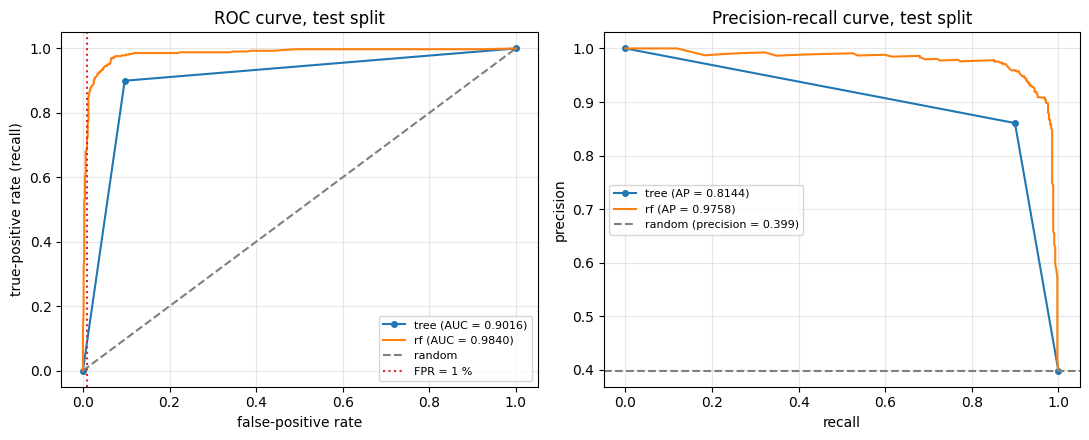

tree: AUC = 0.9016, average precision = 0.8144
rf: AUC = 0.9840, average precision = 0.9758


In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)

tree.fit(X_train, y_train)                       # tree: fitted once here; rf was fitted in Part 1
test_scores = {"tree": tree.predict_proba(X_test)[:, 1], "rf": rf.predict_proba(X_test)[:, 1]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, s in test_scores.items():
    fpr_, tpr_, _ = roc_curve(y_test, s)
    axes[0].plot(fpr_, tpr_, marker="o" if name == "tree" else None, ms=4,
                 label=f"{name} (AUC = {roc_auc_score(y_test, s):.4f})")
    prec_, rec_, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec_, prec_, marker="o" if name == "tree" else None, ms=4,
                 label=f"{name} (AP = {average_precision_score(y_test, s):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="tab:gray", label="random")
axes[0].axvline(0.01, color="tab:red", linestyle=":", label="FPR = 1 %")
axes[0].set(xlabel="false-positive rate", ylabel="true-positive rate (recall)", title="ROC curve, test split")
axes[1].axhline(y_test.mean(), linestyle="--", color="tab:gray", label=f"random (precision = {y_test.mean():.3f})")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall curve, test split")
for ax in axes:
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for name, s in test_scores.items():
    print(f"{name}: AUC = {roc_auc_score(y_test, s):.4f}, average precision = {average_precision_score(y_test, s):.4f}")

### 2.2 A threshold from the training split

In [33]:
from sklearn.model_selection import cross_val_predict

oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fpr_oof, tpr_oof, thr_oof = roc_curve(y_train, oof, drop_intermediate=False)
ok = fpr_oof <= 0.01                                          # candidates: out-of-fold FPR at most 1 %
best_recall = tpr_oof[ok].max()
t = thr_oof[ok & (tpr_oof == best_recall)].max()              # highest recall; the largest threshold if several tie

flag_oof = oof >= t
oof_fpr = flag_oof[y_train == 0].mean()
oof_recall = flag_oof[y_train == 1].mean()
print(f"threshold t (unrounded) : {t!r}")
print(f"out-of-fold FPR at t    : {oof_fpr:.4f}   ({flag_oof[y_train == 0].sum()} of {(y_train == 0).sum()} legitimate training mails)")
print(f"out-of-fold recall at t : {oof_recall:.4f}")
print("same values read from roc_curve:", np.isclose(oof_fpr, fpr_oof[thr_oof == t][0]), np.isclose(oof_recall, tpr_oof[thr_oof == t][0]))

threshold t (unrounded) : np.float64(0.7233333333333334)
out-of-fold FPR at t    : 0.0095   (18 of 1896 legitimate training mails)
out-of-fold recall at t : 0.8123
same values read from roc_curve: True True


### 2.3 Apply it once to the test split

In [34]:
flag_test = test_scores["rf"] >= t
cm = confusion_matrix(y_test, flag_test)
tn, fp, fn, tp = cm.ravel()
display(pd.DataFrame(cm, index=["actually legitimate", "actually spam"], columns=["not flagged", "flagged as spam"]))

test_precision = tp / (tp + fp)
test_recall = tp / (tp + fn)
test_fpr = fp / (fp + tn)
print(f"precision = {test_precision:.4f} | recall = {test_recall:.4f} | FPR = {test_fpr:.4f}")
print(f"{fp} of {fp + tn} legitimate test mails were flagged as spam ({100 * test_fpr:.2f} %); the target was at most 1 %.")
print("1 % target held on the test split:", test_fpr <= 0.01)

,not flagged,flagged as spam
actually legitimate,623,9
actually spam,62,357


precision = 0.9754 | recall = 0.8520 | FPR = 0.0142
9 of 632 legitimate test mails were flagged as spam (1.42 %); the target was at most 1 %.
1 % target held on the test split: False


### 2.4 Importances

In [35]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
imp = pd.DataFrame({"permutation (test, accuracy drop)": perm.importances_mean,
                    "impurity (rf.feature_importances_)": rf.feature_importances_}, index=feature_names)
imp["rank permutation"] = imp.iloc[:, 0].rank(ascending=False).astype(int)
imp["rank impurity"] = imp.iloc[:, 1].rank(ascending=False).astype(int)

print("five highest permutation importances:")
display(imp.sort_values("permutation (test, accuracy drop)", ascending=False).head(5).round(4))
print("five highest impurity importances:")
display(imp.sort_values("impurity (rf.feature_importances_)", ascending=False).head(5).round(4))

five highest permutation importances:


,"permutation (test, accuracy drop)",impurity (rf.feature_importances_),rank permutation,rank impurity
word_freq_remove,0.0371,0.0767,1,3
char_freq_exclam,0.0147,0.1082,2,2
word_freq_hp,0.0142,0.0419,3,9
word_freq_free,0.0090,0.0625,4,4
char_freq_dollar,0.0089,0.1092,5,1


five highest impurity importances:


,"permutation (test, accuracy drop)",impurity (rf.feature_importances_),rank permutation,rank impurity
char_freq_dollar,0.0089,0.1092,5,1
char_freq_exclam,0.0147,0.1082,2,2
word_freq_remove,0.0371,0.0767,1,3
word_freq_free,0.0090,0.0625,4,4
capital_run_length_average,0.0042,0.0620,7,5


In [36]:
feat = "char_freq_dollar"
print(imp.loc[feat, ["rank permutation", "rank impurity"]].to_dict())
train_df = pd.DataFrame(X_train, columns=feature_names)
print("distinct values of", feat, "in X_train:", train_df[feat].nunique(), "| word_freq_remove:", train_df["word_freq_remove"].nunique())
corr = train_df.corr(method="spearman")[feat].drop(feat).abs().sort_values(ascending=False).head(4)
display(corr.round(3).to_frame("|Spearman| with char_freq_dollar"))

{'rank permutation': 5.0, 'rank impurity': 1.0}
distinct values of char_freq_dollar in X_train: 436 | word_freq_remove: 161


,|Spearman| with char_freq_dollar
word_freq_000,0.556
capital_run_length_total,0.515
word_freq_money,0.503
capital_run_length_longest,0.492


**Answers Part 2**

`The curves`
- On the test split the forest has AUC = 0.9840 and average precision = 0.9758; the single tree has AUC = 0.9016 and average precision = 0.8144. The tree's curves are just a few straight segments because a fully grown tree has pure leaves and outputs only 2 distinct scores (probability 0 or 1): it has almost no threshold to choose from, while the forest's averaged probabilities give a fine curve.

`The threshold`
- On the out-of-fold probabilities of the training split the highest recall with FPR ≤ 1 % is reached at t = 0.723333: out-of-fold FPR = 0.0095 (18 of 1896 legitimate training mails) and recall = 0.8123.
- Applied once to the test split: precision = 0.9754, recall = 0.8520, FPR = 0.0142. 9 of 632 legitimate test mails were flagged as spam (1.42 %).

`Did the 1 % target hold on the test split?`
- No. At most 1 % of 632 legitimate mails is 6 mails, and 9 were flagged.
- The miss is small compared with the noise of the estimate: the standard error of an FPR near 1 % on 632 legitimate mails is √(0.01 × 0.99 / 632) = 0.0040, and the test FPR is 1.1 standard errors above 1 %. The threshold was chosen as the best point still under the limit on the training split (out-of-fold FPR 0.0095), that is right at the edge, so it carries no safety margin and a result above the limit on new data is not surprising. The target was not met, and I did not change t afterwards.

`Importances: the two top-five tables, and one feature that ranks differently`
- The two top-five lists share 4 of the five features (`word_freq_remove`, `char_freq_exclam`, `word_freq_free`, `char_freq_dollar`), but in a different order: permutation importance puts `word_freq_remove` first (0.0371), impurity importance puts `char_freq_dollar` first (0.1092); `word_freq_hp` is third by permutation (0.0142) but only rank 9 by impurity.
- I take `char_freq_dollar`: rank 1 by impurity but rank 5 by permutation (shuffling it costs only 0.0089 accuracy, far less than `word_freq_remove`, 0.0371).
- The impurity importance adds up, over all splits of all 300 trees, how much the feature lowered the Gini impurity, measured on the training rows that the trees were grown on. Fully grown trees keep splitting until the leaves are pure, and a feature with many distinct values (436 for `char_freq_dollar`, only 161 for `word_freq_remove`) offers many split points, so it collects impurity decrease at many nodes, including late splits that only fit the training rows. The permutation importance asks a different question: how much does the accuracy on the unseen test split fall when the column is shuffled? If other columns carry much of the same information, the forest can still use them and the fall is small. `char_freq_dollar` is correlated with `word_freq_000`, `capital_run_length_total` and `word_freq_money` (Spearman 0.50 to 0.56 in the table above), which fits this explanation. I have not tested it by removing the feature, so I treat it as the likely reason and not as proved.


# 3. Voting

In [37]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    import numpy as np

    preds = np.array(predictions, dtype=int)               # a copy: the argument is never modified
    if preds.ndim < 2 or preds.shape[1] == 0:
        return np.zeros(0 if preds.ndim < 2 else preds.shape[1], dtype=int)
    n_models, n_samples = preds.shape
    w = np.ones(n_models, dtype=int) if weights is None else np.array(weights)

    labels, inverse = np.unique(preds, return_inverse=True)  # sorted labels: the smallest comes first
    inverse = inverse.reshape(preds.shape)
    counts = np.zeros((len(labels), n_samples), dtype=w.dtype)
    cols = np.arange(n_samples)
    for m in range(n_models):                              # sum of the weights in model order, model 0 first
        counts[inverse[m], cols] += w[m]

    winner = labels[counts.argmax(axis=0)]                 # argmax returns the first maximum: ties go to the smallest label
    winner[counts.max(axis=0) == 0] = 0                    # every count 0 (e.g. all weights 0): the label that nobody predicts, 0, wins
    return winner.astype(int)

In [38]:
# the examples from the task
assert hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]).tolist() == [0, 1, 0]
assert hard_vote([[0, 1], [1, 0]]).tolist() == [0, 0]
assert hard_vote([[0, 1], [1, 0]], weights=[1, 2]).tolist() == [1, 0]
assert hard_vote([[2, 0], [2, 1], [0, 1]]).tolist() == [2, 1]
# edge cases from the rules: all weights 0 -> 0, a zero weight, float weights, arguments unchanged, type and shape
assert hard_vote([[2, 1], [2, 1]], weights=[0, 0]).tolist() == [0, 0]
assert hard_vote([[1, 1], [0, 0]], weights=[0.0, 1.5]).tolist() == [0, 0]
assert hard_vote([[5, 5, 5]], weights=[0.25]).tolist() == [5, 5, 5]
pr = np.array([[0, 1, 1], [0, 1, 0], [1, 1, 0]]); pr_before = pr.copy(); wt = [1, 2, 3]
out = hard_vote(pr, weights=wt)
assert (pr == pr_before).all() and wt == [1, 2, 3] and out.shape == (3,) and np.issubdtype(out.dtype, np.integer)
assert hard_vote(predictions=[[0, 1], [1, 1]], weights=None).tolist() == [0, 1]   # keyword arguments
print("all examples pass👍")

all examples pass👍


### 3.1 Reproduce VotingClassifier(voting="hard")

In [39]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

fitted = {name: clone(model).fit(X_train, y_train) for name, model in members}
member_pred = np.vstack([fitted[name].predict(X_test) for name, _ in members])      # shape (3, n_test)
mine = hard_vote(member_pred)

sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print("shape of the stacked predictions:", member_pred.shape)
print(f"fraction of test rows on which hard_vote and VotingClassifier(voting='hard') agree: {(mine == sk_hard).mean():.4f}")

shape of the stacked predictions: (3, 1051)
fraction of test rows on which hard_vote and VotingClassifier(voting='hard') agree: 1.0000


### 3.2 Disagreement between the members

In [40]:
names = [name for name, _ in members]
rows = []
for i in range(3):
    for j in range(i + 1, 3):
        rows.append({"pair": f"{names[i]} vs {names[j]}", "share of test rows with different labels": (member_pred[i] != member_pred[j]).mean()})
display(pd.DataFrame(rows).set_index("pair").round(4))
for name in names:
    print(f"test accuracy of {name}: {(fitted[name].predict(X_test) == y_test).mean():.4f}")

,share of test rows with different labels
pair,
lr vs knn,0.0514
lr vs tree,0.0847
knn vs tree,0.1018


test accuracy of lr: 0.9296
test accuracy of knn: 0.9258
test accuracy of tree: 0.9020


### 3.3 Cross-validation: members, hard and soft voting

In [41]:
vote_models = {"lr": lr, "knn": knn, "tree": tree,
               "hard voting": VotingClassifier(members, voting="hard"),
               "soft voting": VotingClassifier(members, voting="soft")}
vote_scores = {name: cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
               for name, model in vote_models.items()}
display(fold_table(vote_scores).round(4))

best_member = max(["lr", "knn", "tree"], key=lambda k: vote_scores[k].mean())
print("best member (highest CV mean):", best_member)
print("paired fold differences (accuracy):")
display(paired_table(vote_scores, [("hard voting", best_member), ("soft voting", best_member)]).round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
lr,0.9319,0.9525,0.9366,0.9333,0.9429,0.9394,0.0075
knn,0.9002,0.9445,0.9113,0.9079,0.9302,0.9188,0.0162
tree,0.9113,0.9303,0.9097,0.9000,0.9095,0.9121,0.0099
hard voting,0.9303,0.9572,0.9414,0.9317,0.9492,0.9420,0.0103
soft voting,0.9366,0.9493,0.9477,0.9286,0.9476,0.9420,0.0081


best member (highest CV mean): lr
paired fold differences (accuracy):


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,inside spread
hard voting - lr,-0.001585,0.004754,0.004754,-0.001587,0.006349,0.002537,0.003417,True
soft voting - lr,0.004754,-0.00317,0.011094,-0.004762,0.004762,0.002536,0.005812,True


**Answers Part 3**

`hard_vote against scikit-learn`
- `hard_vote` and `VotingClassifier(voting="hard")` give the same label on 100.00 % of the test rows (fraction 1.0000).
- Pairwise disagreement on the test split: lr vs knn 0.0514, lr vs tree 0.0847, knn vs tree 0.1018. The members disagree on only 5 to 10 % of the mails, and the tree, which is the weakest member, is the one that disagrees most. The mistakes of the three members therefore overlap a lot, and a vote has little room to correct them.

`Does hard voting beat the best member? Does soft voting?` (best member by cross-validation mean: `lr`, 0.9394)
- Hard voting: hard − lr = +0.0025 (std 0.0034), folds [-0.0016, 0.0048, 0.0048, -0.0016, 0.0063]. |mean| is not larger than the std, so the difference is inside the fold spread: I cannot name a winner; the data cannot separate hard voting from lr.
- Soft voting: soft − lr = +0.0025 (std 0.0058), folds [0.0048, -0.0032, 0.0111, -0.0048, 0.0048]. |mean| is not larger than the std, so the difference is inside the fold spread: no winner here either; the data cannot separate soft voting from lr.
- Both ensembles have a mean 0.9420 and 0.9420 against 0.9394 for lr, and each is better on 3 and 3 of 5 folds, but with that spread I cannot say it is more than chance on these folds.


# 4. Stacking

### 4.1 Out-of-fold stacking by hand, against StackingClassifier

In [42]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

Z_oof = np.column_stack([cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
                         for _, model in members])
meta = LogisticRegression().fit(Z_oof, y_train)

Z_test = np.column_stack([fitted[name].predict_proba(X_test)[:, 1] for name, _ in members])   # members fitted on the full training split in Part 3
my_pred = meta.predict(Z_test)

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
sk_pred = stack.predict(X_test)

print("shape of the out-of-fold matrix:", Z_oof.shape)
print("my coefficients       :", meta.coef_.ravel().round(4))
print("StackingClassifier    :", stack.final_estimator_.coef_.ravel().round(4))
print("largest absolute difference between the two coefficient vectors:", np.abs(meta.coef_ - stack.final_estimator_.coef_).max())
print("test predictions identical:", np.array_equal(my_pred, sk_pred))
print(f"test accuracy, my stacking: {(my_pred == y_test).mean():.4f} | StackingClassifier: {stack.score(X_test, y_test):.4f}")

shape of the out-of-fold matrix: (3153, 3)
my coefficients       : [3.6346 2.8996 1.6895]
StackingClassifier    : [3.6346 2.8996 1.6895]
largest absolute difference between the two coefficient vectors: 0.0
test predictions identical: True
test accuracy, my stacking: 0.9324 | StackingClassifier: 0.9324


### 4.2 Naive stacking (probabilities of rows the members were fitted on)

In [43]:
Z_naive = np.column_stack([clone(model).fit(X_train, y_train).predict_proba(X_train)[:, 1] for _, model in members])
meta_naive = LogisticRegression().fit(Z_naive, y_train)

coef_table = pd.DataFrame({"naive (in-sample probabilities)": meta_naive.coef_.ravel(),
                           "out-of-fold probabilities": meta.coef_.ravel()}, index=names)
display(coef_table.round(4))
print("intercepts: naive", meta_naive.intercept_.round(3), "| out-of-fold", meta.intercept_.round(3))
for k, name in enumerate(names):
    print(f"training accuracy of {name} on its own training rows: {((Z_naive[:, k] >= 0.5) == y_train).mean():.4f}"
          f" | out-of-fold accuracy: {((Z_oof[:, k] >= 0.5) == y_train).mean():.4f}")

,naive (in-sample probabilities),out-of-fold probabilities
lr,1.9554,3.6346
knn,1.7858,2.8996
tree,8.2925,1.6895


intercepts: naive [-6.013] | out-of-fold [-3.993]
training accuracy of lr on its own training rows: 0.9458 | out-of-fold accuracy: 0.9394
training accuracy of knn on its own training rows: 0.9315 | out-of-fold accuracy: 0.9188
training accuracy of tree on its own training rows: 1.0000 | out-of-fold accuracy: 0.9121


### 4.3 Cross-validation: stacking, soft voting, best member

In [44]:
stack_scores = {"stack": cross_validate(stack, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
                "soft voting": vote_scores["soft voting"],
                best_member: vote_scores[best_member]}        # soft voting and the best member: same folds as in Part 3
display(fold_table(stack_scores).round(4))
print("paired fold differences (accuracy):")
display(paired_table(stack_scores, [("stack", best_member), ("stack", "soft voting")]).round(4))

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
stack,0.9398,0.9540,0.9461,0.9349,0.9460,0.9442,0.0065
soft voting,0.9366,0.9493,0.9477,0.9286,0.9476,0.9420,0.0081
lr,0.9319,0.9525,0.9366,0.9333,0.9429,0.9394,0.0075


paired fold differences (accuracy):


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,inside spread
stack - lr,0.007924,0.001585,0.009509,0.001587,0.003175,0.004756,0.003323,False
stack - soft voting,0.00317,0.004754,-0.001585,0.006349,-0.001587,0.00222,0.003266,True


**Answers Part 4**

`My own out-of-fold stacking against StackingClassifier`
- The largest absolute difference between the two coefficient vectors is 0.0e+00, the test predictions are identical, and the test accuracies are 0.9324 (mine) and 0.9324 (StackingClassifier). The hand-built version is the same model.

`(a) How does the tree's weight differ between the naive and the out-of-fold fit, and why?`
- The tree's coefficient is 8.29 in the naive fit and 1.69 in the out-of-fold fit. In the naive fit it is the largest by far (4.2 times the weight of logistic regression); in the out-of-fold fit it is the smallest of the three.
- Reason: a fully grown tree reproduces its own training rows (its accuracy on the rows it was fitted on is 1.0000), so on those rows its probabilities are always right and the meta-learner learns that the tree can be trusted. On rows the tree has not seen (out-of-fold) it is right only 0.9121 of the time, which is the lowest of the three members, and the meta-learner gives it the lowest weight. Logistic regression (0.9458 in-sample against 0.9394 out-of-fold) and k-nearest neighbours (0.9315 against 0.9188) are close in-sample and out-of-fold, so their probabilities mean about the same in both fits; their coefficients still rise (1.96 → 3.63 and 1.79 → 2.90) because they now have to carry the decision that the tree no longer dominates. The naive stack would trust the member that overfits most, and it would do so only because it is graded on rows that member has already seen.

`(b) Does stacking beat the best member, and does it beat soft voting?`
- Against the best member: stack − lr = +0.0048 (std 0.0033), better on 5 of 5 folds; |mean| is larger than the std, so it is outside the fold spread. Stacking is better than lr here, but the gain is small: 0.48 percentage points of accuracy.
- Against soft voting: stack − soft voting = +0.0022 (std 0.0033), better on 3 of 5 folds; |mean| is not larger than the std, so it is inside the fold spread. No winner: the data cannot separate stacking from soft voting.
